<a href="https://colab.research.google.com/github/SonnyZhan/llm-distillation-finance/blob/main/LLM_distillation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
!pip install -q anthropic datasets sentence-transformers scikit-learn gradio
!pip install "datasets<4.0"

In [15]:
import os
from google.colab import userdata
os.environ["ANTHROPIC_API_KEY"] = userdata.get("ANTHROPIC_API_KEY")
print("Key loaded: ", os.environ["ANTHROPIC_API_KEY"][:2] + "...")

Key loaded:  sk...


In [91]:
#libraries
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.linear_model import LogisticRegression

import anthropic

import time
from tqdm.auto import tqdm

#encoder
from sentence_transformers import SentenceTransformer

#save model
import joblib

#web demo
import gradio as gr

In [21]:
rows = []
with open("/content/sample_data/Sentences_AllAgree.txt", encoding="latin-1") as f:
  for line in f:
    line = line.strip()
    if line:
      sentence, label = line.rsplit("@", 1)
      rows.append({"sentence": sentence, "label_name": label})

df = pd.DataFrame(rows)
print("Total sentences: ", len(df))
print(df["label_name"].value_counts())
df.head(5)

Total sentences:  2264
label_name
neutral     1391
positive     570
negative     303
Name: count, dtype: int64


,sentence,label_name
0,"According to Gran , the company has no plans t...",neutral
1,"For the last quarter of 2010 , Componenta 's n...",positive
2,"In the third quarter of 2010 , net sales incre...",positive
3,Operating profit rose to EUR 13.1 mn from EUR ...,positive
4,"Operating profit totalled EUR 21.1 mn , up fro...",positive


In [29]:
train, test = train_test_split(
    df,
    test_size=400,
    stratify=df["label_name"],
    random_state=42)
train = train.sample(n=600, random_state=42).reset_index(drop=True)
test = test.reset_index(drop=True)
print("Training len: ", len(train), train.head(3))
print("Testing len: ", len(test), test.head(3))

Training len:  600                                             sentence label_name
0  Valmet Automotive reports net sales of EUR 85m...    neutral
1  Apartments of YIT Home may be purchased in 5 r...    neutral
2  Return on equity stood at 18.3 % compared to 1...   positive
Testing len:  400                                             sentence label_name
0  In the third quarter of 2010 , net sales incre...   positive
1  They will be sunk to a depth of some 360-380 m...    neutral
2  The company says the measures are no longer ne...    neutral


In [41]:
#The teacher LLM that labels
client = anthropic.Anthropic()
MODEL = "claude-haiku-5-5"

PROMPT = """You are a financial analyst. Read this sentence from a financial news article
and decide its sentiment from an investor's point of view.
Answer with exactly one word: positive, negative, or neutral.

Sentence: {sentence}"""

def ask_teacher_llm(sentence):
    response = client.messages.create(
        model=MODEL,
        max_tokens=5,
        thinking={"type": "disabled"},
        messages=[{"role": "user", "content": PROMPT.format(sentence=sentence)}],
    )
    answer = response.content[0].text.strip().lower()
    for label in ["positive", "negative", "neutral"]:
        if label in answer:
            return label
    return "neutral"

print(ask_teacher_llm(
    "For the last quarter of 2010 , Componenta 's net sales "
    "doubled to EUR131m from EUR76m for the same period a year earlier , "
    "while it moved to a zero pre-tax profit from a pre-tax loss of EUR7m ."
))

positive


In [42]:
def label_with_teacher(frame, cache_file):
  if os.path.exists(cache_file):
    print("Loading saved label from: ", cache_file)
    return pd.read_csv(cache_file)

  labels, seconds = [], []
  for sentence in tqdm(frame["sentence"]):
    start = time.perf_counter()
    labels.append(ask_teacher_llm(sentence))
    seconds.append(time.perf_counter() - start)

  res = frame.copy()
  res["teacher_label"] = labels
  res["teacher_seconds"] = seconds
  res.to_csv(cache_file, index=False)
  return res

In [43]:
train = label_with_teacher(train, "train_teacher_labels.csv")
test = label_with_teacher(test, "test_teacher_labels.csv")

  0%|          | 0/600 [00:00<?, ?it/s]

  0%|          | 0/400 [00:00<?, ?it/s]

In [45]:
teacher_acc = accuracy_score(test["label_name"], test["teacher_label"])
teacher_f1 = f1_score(test["label_name"], test["teacher_label"], average="macro")

print(f"Teacher acc: {teacher_acc:.1%}")
print(f"Teacher f1: {teacher_f1:.1%}")

Teacher acc: 95.2%
Teacher f1: 94.4%


In [50]:
#turn sentences to embeddings (384) then we classifiy
encoder = SentenceTransformer("all-MiniLM-L6-v2")

X_train = encoder.encode(train["sentence"].tolist(), show_progress_bar=True)
X_test = encoder.encode(test["sentence"].tolist(), show_progress_bar=True)
print(f"X_train: {X_train.shape}")
print(f"X_test: {X_test.shape}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/19 [00:00<?, ?it/s]

Batches:   0%|          | 0/13 [00:00<?, ?it/s]

X_train: (600, 384)
X_test: (400, 384)


In [79]:
student = LogisticRegression(max_iter=1000, class_weight="balanced")
student.fit(X_train, train['teacher_label'])
student_preds = student.predict(X_test)

human_student = LogisticRegression(max_iter=1000, class_weight="balanced")
human_student.fit(X_train, train['label_name'])
human_preds = human_student.predict(X_test)

In [80]:
student_acc = accuracy_score(test['label_name'], student_preds)
student_f1 = f1_score(test['label_name'], student_preds, average='weighted')

human_acc = accuracy_score(test['label_name'], human_preds)
human_f1 = f1_score(test['label_name'], human_preds, average='weighted')

#comparison acc and f1
print("Performance Comparison:")
print(f"LLM labels: ACC={student_acc:.2f}, F1={student_f1:.2f}")
print(f"Human labels: ACC={human_acc:.2f}, F1={human_f1:.2f}")

Performance Comparison:
LLM labels: ACC=0.82, F1=0.83
Human labels: ACC=0.87, F1=0.87


In [81]:
#comparison speed
start = time.perf_counter()
student.predict(encoder.encode(test['sentence'].tolist()))
student_ms = (time.perf_counter() - start) / len(test) * 1000

teacher_ms = test['teacher_seconds'].mean() * 1000

#our smaller way simplier model is way fast than large LLM
print(f"Teacher: {teacher_ms:.0f} ms per sentence")
print(f"Student: {student_ms:.0f} ms per sentence")

Teacher: 913 ms per sentence
Student: 2 ms per sentence


In [82]:
def score(name, acc, f1, ms):
  return {
      "model": name,
      "acc": acc,
      "f1": f1,
      "ms_per_sentence": ms,
  }

res = pd.DataFrame([
    score("Teacher (big LLM)", teacher_acc, teacher_f1, teacher_ms),
    score("Student (LLM label)", student_acc, student_f1, student_ms),
    score("Student (Human label)", human_acc, human_f1, student_ms)
])

res.round(3)

,model,acc,f1,ms_per_sentence
0,Teacher (big LLM),0.952,0.944,912.925
1,Student (LLM label),0.825,0.829,1.601
2,Student (Human label),0.870,0.871,1.601


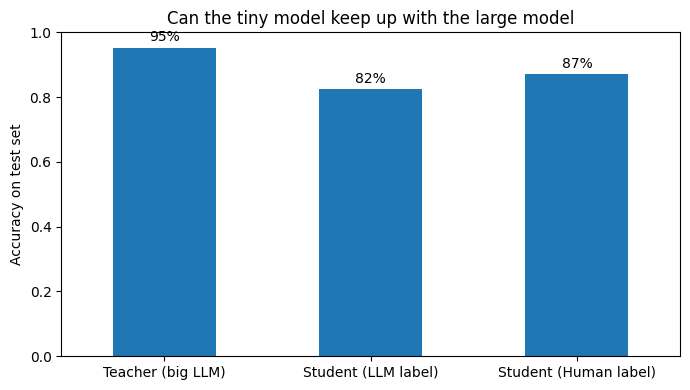

In [83]:
ax = res.plot.bar(x="model", y="acc", legend=False, ylim=(0, 1), rot=0, figsize=(7,4))
ax.set_ylabel("Accuracy on test set")
ax.set_xlabel("")
ax.set_title("Can the tiny model keep up with the large model")
for i, v in enumerate(res['acc']):
  ax.text(i, v + 0.02, f"{v:.0%}", ha="center")
plt.tight_layout()
plt.savefig("res.png", dpi=150)

In [84]:
test['student_pred'] = student_preds
mistakes = test[test['student_pred'] != test['label_name']]
mistakes[['sentence', 'label_name', 'teacher_label', 'student_pred']].head(10)

,sentence,label_name,teacher_label,student_pred
1,They will be sunk to a depth of some 360-380 m...,neutral,neutral,negative
6,Tekla Group 's net sales for 2006 were approxi...,neutral,positive,positive
23,"In April-June 2008 , Scanfil 's net sales tota...",neutral,positive,positive
27,The company had net sales of EUR 19.8 mn and a...,neutral,positive,positive
35,These moderate but significant changes resulte...,positive,positive,negative
43,Major Order in India Comptel Corporation has r...,positive,positive,neutral
44,"Ragutis , which is based in Lithuania 's secon...",positive,positive,neutral
49,The medium-term operative targets of the compa...,neutral,neutral,negative
58,Following this increase Huhtamaki 's registere...,neutral,neutral,positive
78,Stora is due to release its fourth-quarter and...,neutral,neutral,positive


In [86]:
joblib.dump(student, 'student.joblib')
def predict(sentence):
  vec = encoder.encode([sentence])
  probs = student.predict_proba(vec)[0]

  return {label: float(p) for label, p in zip(student.classes_, probs)}

In [88]:
#predicted wrong from above: (neutral)
predict("They will be sunk to a depth of some 360-380 metres and fixed to the bottom mud by vacuum .")

{'negative': 0.22995445787873434,
 'neutral': 0.10650020193392315,
 'positive': 0.6635453401873426}

In [90]:
#predicted right from above: (positive)
predict(
    "For the last quarter of 2010 , Componenta 's net sales "
    "doubled to EUR131m from EUR76m for the same period a year earlier , "
    "while it moved to a zero pre-tax profit from a pre-tax loss of EUR7m ."
)

{'negative': 0.22995445787873434,
 'neutral': 0.10650020193392315,
 'positive': 0.6635453401873426}

In [96]:
#web demo
demo = gr.Interface(
    fn=predict,
    inputs=gr.Textbox(label="Financial news sentence"),
    outputs=gr.Label(label="Sentiment"),
    title="Tiny finance sentiment model (distilled from LLM)",
    description="A small model trained only on label written by a larger LLM",
    examples=[
        "Sales increased by 20% compared to past years",
        "The company will lay off 200 employees as demand decreased",
        "The annual general meeting will be held next week",
    ],
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://52b99d5db0279d92b5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
